# Rebalance Pitch EDA: does month-end 60/40 rebalancing still move stocks vs bonds?

**The mechanism.** About $20tn of pension and target-date money follows fixed stock/bond targets and rebalances on a
calendar (month- or quarter-end) or when a threshold is breached. If stocks beat bonds during the month, these funds
must **sell stocks and buy bonds** at month-end, and the size is a formula of the month-to-date return gap. The
schedule is public, the trade is mandated, and committees do not change their rules even knowing they are
front-run.

**The paper.** Harvey, Mazzoleni & Melone, *"The Unintended Consequences of Rebalancing"* (NBER w33554, 2025;
sample 1997–2023): when stocks are overweight, equity returns fall about **17bp the next day**; they estimate the
cost to investors at about $16bn a year.

**Questions.**
1. Does the month-to-date stock-minus-bond gap, measured *before* month-end, predict stock-minus-bond returns into
   and just after month-end?
2. Is it specific to month-ends (placebo: mid-month), and bigger at quarter-ends?
3. Is it still there outside the paper's sample: 1990–96 (before) and 2024–26 (after publication)?
4. Tradable: long/short stocks vs bonds (ES vs ZN, or SPY vs IEF), net of cost.

**Data.** `etfs.csv` (SPY, IEF, TLT, AGG, S&P 500 index; Yahoo), `dgs10.csv` (FRED). Bonds before IEF (2002) use a
10-year yield proxy: carry $y/252$ minus duration 7.5 × the yield change.

**Realism rules.** Month-end dates are calendar facts. The signal at the close of day $T-k$ uses closes up to $T-k$
only; the trade is entered at that close and earns returns from $T-k+1$ on.

## 1. Data

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
DATA = Path("data")
e = pd.read_csv(DATA / "etfs.csv", parse_dates=["date"]).pivot(index="date", columns="ticker", values="adj_close")
y10 = pd.read_csv(DATA / "dgs10.csv", parse_dates=["date"]).set_index("date").DGS10
y10 = pd.to_numeric(y10, errors="coerce")
cal = e.index[e.index >= "1990-01-01"]
S = e.SPY.pct_change().reindex(cal)
S = S.fillna(e["^GSPC"].pct_change().reindex(cal) + 0.025 / 252)            # pre-1993: index + ~2.5% dividend yield
yy = y10.reindex(cal).ffill()
B_proxy = yy.shift(1) / 100 / 252 - 7.5 * yy.diff() / 100
B = e.IEF.pct_change().reindex(cal).fillna(B_proxy)
X = (S - B) * 1e4                                                            # stock minus bond, bp
ym = cal.to_period("M")
last = pd.Series(cal, index=cal).groupby(ym).transform("max") == pd.Series(cal, index=cal)   # last trading day of month
pos_in_month = pd.Series(np.arange(len(cal)), index=cal).groupby(ym).transform(lambda s: s - s.max())   # 0 = month-end, -1 = day before ...
first_after = pd.Series(np.arange(len(cal)), index=cal).groupby(ym).transform(lambda s: s - s.min() + 1)  # 1 = first day of month
PERIOD = pd.cut(cal.year, [1989, 1996, 2023, 2026], labels=["1990–96 (pre-sample)", "1997–2023 (paper)", "2024– (post)"])
print(f"{len(cal)} days {cal[0].date()} .. {cal[-1].date()}; months: {ym.nunique()}")

9265 days 1990-01-02 .. 2026-10-15; months: 442


## 2. The signal: how far a 60/40 portfolio has drifted
**What this does.** For a 60/40 portfolio rebalanced at the previous month-end close, the equity weight at the close of
day $t$ is $w_t = 0.6(1+R^S)/(0.6(1+R^S)+0.4(1+R^B))$ with month-to-date returns $R$. The drift $d_t = w_t - 0.6$
(percentage points) is the overweight that month-end rebalancing must sell. Known at the close of $t$.

month-end drift (pp):  {'count': 442.0, 'mean': 0.1, 'std': 1.12, 'min': -4.64, '25%': -0.4, '50%': 0.19, '75%': 0.77, 'max': 2.9}


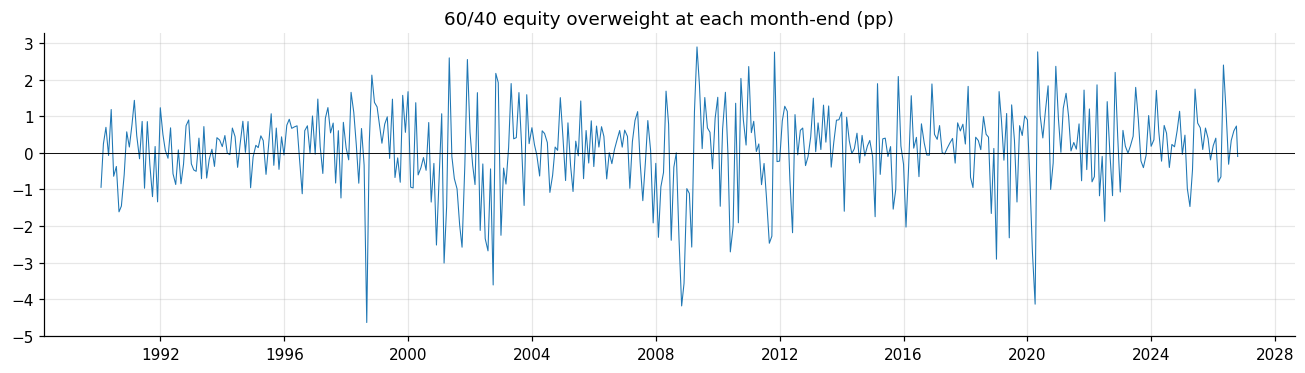

In [2]:
gs = (1 + S).groupby(ym).cumprod(); gb = (1 + B).groupby(ym).cumprod()
drift = (0.6 * gs / (0.6 * gs + 0.4 * gb) - 0.6) * 100           # pp, at each close, month-to-date
D = pd.DataFrame({"X": X, "drift": drift, "pos": pos_in_month, "first": first_after, "last": last, "period": PERIOD}, index=cal)
me = D[D["last"]]
print("month-end drift (pp): ", me.drift.describe().round(2).to_dict())
fig, ax = plt.subplots(figsize=(12, 3.5)); ax.plot(me.index, me.drift, lw=0.7); ax.axhline(0, c="k", lw=0.6)
ax.set_title("60/40 equity overweight at each month-end (pp)"); plt.tight_layout(); plt.show()

## 3. Does drift predict stock-minus-bond returns around month-end?
**What this does.** For each month, the drift known at the close of day $T-k$ (T = month-end) against the
stock-minus-bond return over three windows: **into month-end** ($T-k \to T$, k = 1…5), and **after** ($T \to T+1$,
$T \to T+3$). The rebalancing story predicts a **negative** slope. Placebo: the same regression around the 15th
trading-day of the month instead of month-end. Newey–West errors.

In [3]:
idx = np.arange(len(cal)); Xv = X.values; dv = drift.values
me_i = idx[last.values]
mid_i = idx[(first_after.values == 15)]
def window(i0, i1):
    return Xv[i0 + 1:i1 + 1].sum()                 # returns of days i0+1 .. i1 (enter close i0, exit close i1)
rows = []
for name, sig_off, a, b in [("into ME: k=5", -5, -5, 0), ("into ME: k=3", -3, -3, 0), ("into ME: k=1", -1, -1, 0),
                            ("after ME: T->T+1", 0, 0, 1), ("after ME: T->T+3", 0, 0, 3), ("ME-1 -> T+1", -1, -1, 1)]:
    rec = []
    for T in me_i:
        if T + a < 1 or T + b >= len(cal):
            continue
        rec.append((cal[T], dv[T + sig_off], window(T + a, T + b), PERIOD[T]))
    r = pd.DataFrame(rec, columns=["date", "drift", "y", "period"])
    for per in [None] + list(PERIOD.categories):
        d = r if per is None else r[r.period == per]
        f = sm.OLS(d.y, sm.add_constant(d.drift)).fit(cov_type="HAC", cov_kwds={"maxlags": 2})
        rows.append({"window": name, "period": per or "all", "n": len(d), "slope bp per pp": f.params.drift, "t": f.tvalues.drift})
res = pd.DataFrame(rows)
print(res.round(2).to_string(index=False))

# placebo: mid-month (15th trading day)
rec = [(dv[T - 1], window(T - 1, T + 1)) for T in mid_i if T + 1 < len(cal)]
r = pd.DataFrame(rec, columns=["drift", "y"])
f = sm.OLS(r.y, sm.add_constant(r.drift)).fit(cov_type="HAC", cov_kwds={"maxlags": 2})
print(f"\nplacebo mid-month (day 14 -> 16): slope {f.params.drift:+.2f} bp per pp (t {f.tvalues.drift:+.2f})")

          window               period   n  slope bp per pp     t
    into ME: k=5                  all 442           -78.43 -3.50
    into ME: k=5 1990–96 (pre-sample)  84           -23.21 -1.16
    into ME: k=5    1997–2023 (paper) 324           -83.35 -3.55
    into ME: k=5         2024– (post)  34           -22.78 -0.47
    into ME: k=3                  all 442           -34.32 -3.21
    into ME: k=3 1990–96 (pre-sample)  84            -9.24 -0.52
    into ME: k=3    1997–2023 (paper) 324           -36.43 -3.12
    into ME: k=3         2024– (post)  34           -20.36 -0.67
    into ME: k=1                  all 442           -16.32 -2.20
    into ME: k=1 1990–96 (pre-sample)  84           -23.49 -2.09
    into ME: k=1    1997–2023 (paper) 324           -14.70 -1.76
    into ME: k=1         2024– (post)  34           -43.46 -3.25
after ME: T->T+1                  all 441            15.98  1.63
after ME: T->T+1 1990–96 (pre-sample)  84           -11.90 -0.94
after ME: T->T+1    1997–

**Interpretation.**
- **The paper's window works in the paper's sample and nowhere else.** Drift known at $T-5$ against stock-minus-bond
  over $T-5 \to T$: −83bp per pp (t = −3.6) in 1997–2023, but −23 (t = −1.2) in 1990–96 and −23 (t = −0.5) after
  publication.
- **After month-end the sign flips** (T → T+1: +18, t = 1.7). Rebalancing pressure partly reverses the next day, so
  $T-1 \to T+1$ nets to zero.
- **The only window negative in all three periods is the month-end day itself** ($T-1 \to T$): −23 (t −2.1), −15
  (t −1.8), −43 (t −3.3). It was not the strongest in-sample window, so choosing it now is partly hindsight.
- The mid-month placebo is flat (t −0.1).

## 3b. Day by day, and the month-end-day trade
**What this does.** Single-day slopes on drift fixed at the close of $T-6$ (known before every day shown), and the
simplest calendar-rebalancer trade: at the close of $T-1$ fade the drift (short stocks / long bonds if $d>0$), exit
at the close of $T$, net 4bp round trip. Mid-month placebos for both windows.

In [4]:
print("single-day slope on drift known at close T-6 (bp per pp):")
for j in range(-5, 4):
    rec = [(dv[T - 6], Xv[T + j], PERIOD[T]) for T in me_i if T - 6 >= 0 and T + j < len(cal)]
    r = pd.DataFrame(rec, columns=["d", "y", "p"]); line = f"day {j:+d}: "
    for per in PERIOD.categories:
        d = r[r.p == per]; f = sm.OLS(d.y, sm.add_constant(d.d)).fit(cov_type="HC1")
        line += f"{per[:9]} {f.params.d:+6.1f} (t {f.tvalues.d:+.1f})  "
    print(line)
for nm, (so, a, b) in {"mid-month k=1": (-1, -1, 0), "mid-month k=5": (-5, -5, 0)}.items():
    rec = [(dv[T + so], window(T + a, T + b)) for T in mid_i if T + so >= 0]
    r = pd.DataFrame(rec, columns=["d", "y"]); f = sm.OLS(r.y, sm.add_constant(r.d)).fit(cov_type="HAC", cov_kwds={"maxlags": 2})
    print(f"{nm} placebo: slope {f.params.d:+.1f} (t {f.tvalues.d:+.2f})")
rec = [(cal[T], dv[T - 1], Xv[T], PERIOD[T]) for T in me_i]
r = pd.DataFrame(rec, columns=["date", "d", "y", "p"]); r["pnl"] = -np.sign(r.d) * r.y - 4
for per in PERIOD.categories:
    q = r[r.p == per].pnl
    print(f"month-end-day fade, {per}: {q.mean():+.1f}bp/trade (t {q.mean() / q.std() * np.sqrt(len(q)):+.2f}), hit {(q > 0).mean():.0%}, Sharpe (12/yr) {q.mean() / q.std() * np.sqrt(12):+.2f}, n={len(q)}")

single-day slope on drift known at close T-6 (bp per pp):
day -5: 1990–96 (  -17.3 (t -1.3)  1997–2023   -5.4 (t -0.3)  2024– (po  -22.4 (t -0.8)  
day -4: 1990–96 (   -4.9 (t -0.3)  1997–2023   +1.2 (t +0.1)  2024– (po  -20.5 (t -1.0)  
day -3: 1990–96 (   -9.6 (t -0.9)  1997–2023  -50.8 (t -3.9)  2024– (po  +17.3 (t +1.0)  
day -2: 1990–96 (   -1.0 (t -0.1)  1997–2023   -5.9 (t -0.5)  2024– (po   +0.8 (t +0.1)  
day -1: 1990–96 (  +17.1 (t +1.1)  1997–2023  -11.9 (t -1.5)  2024– (po  +22.3 (t +0.9)  
day +0: 1990–96 (  -26.5 (t -2.7)  1997–2023  -10.9 (t -1.7)  2024– (po  -27.4 (t -1.3)  
day +1: 1990–96 (   -1.8 (t -0.1)  1997–2023  +33.7 (t +2.8)  2024– (po   +7.6 (t +0.4)  
day +2: 1990–96 (   +3.4 (t +0.3)  1997–2023   +2.2 (t +0.2)  2024– (po   +0.5 (t +0.0)  
day +3: 1990–96 (  +33.0 (t +3.1)  1997–2023   +7.2 (t +0.8)  2024– (po  +36.2 (t +0.7)  
mid-month k=1 placebo: slope +5.1 (t +0.40)
mid-month k=5 placebo: slope +35.5 (t +1.33)
month-end-day fade, 1990–96 (pre-sample): +

**Interpretation.**
- The month-end day is negative in every period (−27 t −2.7; −11 t −1.7; −27 t −1.3), but the paper-era pattern also
  has a large unexplained day −3 (−51, t −3.9) that shows up nowhere else, and a +34 (t 2.8) day +1 reversal.
- The month-end-day fade nets +5bp (t 0.8) in 1990–96, +14bp (t 2.0) in 1997–2023 and +31bp (t 2.0, n = 34) after
  publication. Sharpe is 0.3–0.4 per year over the long sample: one day a month, small.

## 4. Quarter-ends and big drifts
**What this does.** Splits month-ends into quarter-ends vs other months, and sorts by the size of the drift known at
$T-1$ (thresholds trigger bigger trades). Outcome: stock-minus-bond from the close of $T-1$ to the close of $T+1$.

In [5]:
rec = []
for T in me_i:
    if T + 1 >= len(cal): continue
    rec.append({"date": cal[T], "drift": dv[T - 1], "y": window(T - 1, T + 1), "q_end": cal[T].month in (3, 6, 9, 12), "period": PERIOD[T]})
R = pd.DataFrame(rec)
R["db"] = pd.cut(R.drift, [-100, -2, -1, -0.3, 0.3, 1, 2, 100])
print(R.groupby("db", observed=True).y.agg(["mean", "count", lambda x: x.mean() / x.sem()]).rename(columns={"<lambda_0>": "t"}).round(2).to_string())
for q in [True, False]:
    d = R[R.q_end == q]
    f = sm.OLS(d.y, sm.add_constant(d.drift)).fit(cov_type="HC1")
    print(f"{'quarter-end' if q else 'other months'}: slope {f.params.drift:+.2f} bp/pp (t {f.tvalues.drift:+.2f}), n={len(d)}")

                 mean  count     t
db                                
(-100.0, -2.0] -68.31     24 -0.88
(-2.0, -1.0]    62.62     39  1.47
(-1.0, -0.3]     9.06     62  0.41
(-0.3, 0.3]     10.35    109  0.70
(0.3, 1.0]       4.15    132  0.43
(1.0, 2.0]      41.11     58  2.01
(2.0, 100.0]   -62.01     17 -1.11
quarter-end: slope -16.98 bp/pp (t -0.72), n=147


other months: slope +8.14 bp/pp (t +0.51), n=294


## 5. Tradable version
**Rule.** At the close of $T-1$ (the day before month-end), if $|d| \ge \theta$ pp, go short stocks / long bonds
when $d>0$ (and the reverse when $d<0$), dollar-neutral, exit at the close of $T+1$. Cost 1bp per leg per side (ES/ZN
futures are cheaper; SPY/IEF about this). $\theta$ chosen on 1997–2023; reported on 1990–96 and 2024–.

 theta               period  trades  bp/trade     t  hit  ann. Sharpe (12/yr)
   0.0 1990–96 (pre-sample)      84      4.40  0.46 0.54                 0.17
   0.0    1997–2023 (paper)     324     -7.68 -0.67 0.45                -0.13
   0.0         2024– (post)      33     15.59  0.72 0.52                 0.43
   0.5 1990–96 (pre-sample)      43     12.86  0.89 0.60                 0.47
   0.5    1997–2023 (paper)     203     -4.07 -0.26 0.43                -0.06
   0.5         2024– (post)      22     19.87  0.71 0.45                 0.53
   1.0 1990–96 (pre-sample)      13     53.78  1.74 0.85                 1.67
   1.0    1997–2023 (paper)     116    -15.51 -0.62 0.41                -0.20
   1.0         2024– (post)       9      2.25  0.05 0.33                 0.05
   1.5 1990–96 (pre-sample)       2    229.20   NaN 1.00                  NaN
   1.5    1997–2023 (paper)      72    -30.22 -0.85 0.38                -0.35
   1.5         2024– (post)       4    -49.79 -1.80 0.25        

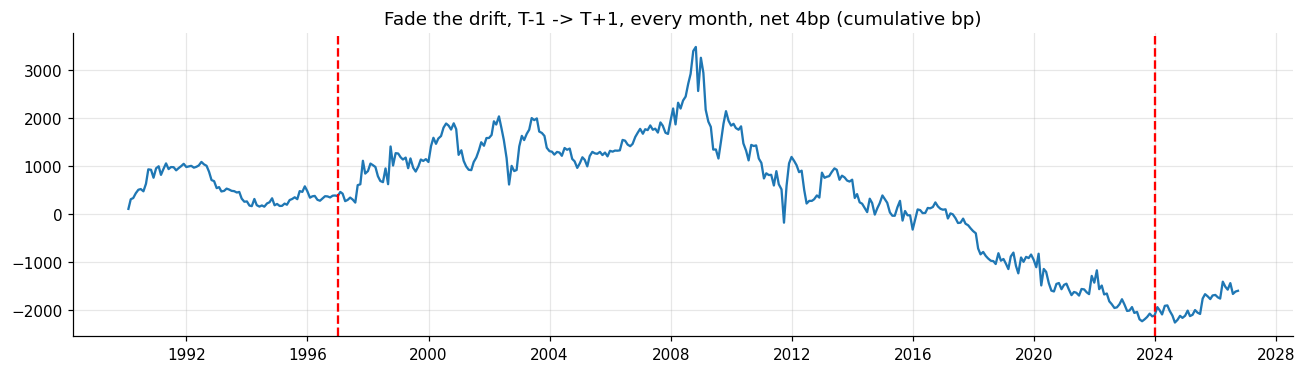

by year (theta 0): {2015: -712.0, 2016: 415.0, 2017: -446.0, 2018: -583.0, 2019: -19.0, 2020: -521.0, 2021: 46.0, 2022: -455.0, 2023: -229.0, 2024: -6.0, 2025: 435.0, 2026: 87.0}


In [6]:
def run(theta, cost=2.0, d=R):
    t = d[d.drift.abs() >= theta]
    return (-np.sign(t.drift) * t.y - 2 * cost), t
out = []
for th in [0, 0.5, 1, 1.5, 2, 3]:
    for per in PERIOD.categories:
        p, t = run(th, d=R[R.period == per])
        out.append({"theta": th, "period": per, "trades": len(p), "bp/trade": p.mean(), "t": p.mean() / p.std() * np.sqrt(len(p)) if len(p) > 2 else np.nan,
                    "hit": (p > 0).mean(), "ann. Sharpe (12/yr)": p.mean() / p.std() * np.sqrt(12) if len(p) > 2 else np.nan})
print(pd.DataFrame(out).round(2).to_string(index=False))
p, t = run(0)
fig, ax = plt.subplots(figsize=(12, 3.5)); ax.plot(t.date, p.cumsum()); ax.set_title("Fade the drift, T-1 -> T+1, every month, net 4bp (cumulative bp)")
for x in ["1997-01-01", "2024-01-01"]: ax.axvline(pd.Timestamp(x), c="r", ls="--")
plt.tight_layout(); plt.show()
print("by year (theta 0):", p.groupby(t.date.dt.year).sum().round(0).loc[2015:].to_dict())

**Interpretation.**
- **No monotone size effect.** Big drifts (|d| > 2pp) go the wrong way. Quarter-ends are not stronger (t −0.7). The
  threshold rule loses in the paper sample at every θ.

## 6. Takeaways

| question | answer |
|---|---|
| Paper's effect (drift → stocks lag bonds into month-end) | **In-sample only.** t −3.6 in 1997–2023, −1.2 before, −0.5 after publication. |
| Month-end day itself | Negative in every period; the fade earns +14bp/trade (t 2.0) 1997–2023 and +31bp (t 2.0, 34 months) since 2024, but it was not the in-sample-best window. |
| Size / quarter-end | No dose-response; quarter-ends not stronger. |
| Tradable | **Weak.** Sharpe about 0.3–0.4/yr on a one-day-a-month trade; only the post-publication 34 months look good. |

**Verdict: not promising enough.** It is noted as a weak candidate (month-end-day fade) to recheck once more
post-publication data exists, but it fails the in-sample-chosen test.